# DBSCAN Clustering — Machine Fault Data (Pure Acoustic Features)

**No neural network used.** Features are extracted directly from raw `.wav` files using classical signal processing:
- MFCCs (40 coefficients × mean + std + delta mean) → 120 dims
- Spectral centroid, bandwidth, rolloff, flatness → 8 dims
- Zero-crossing rate → 2 dims
- RMS energy → 2 dims
- Chroma (12 × mean + std) → 24 dims
- Mel-spectrogram statistics (mean + std per band, 32 bands) → 64 dims
- Tonnetz → 12 dims

**Total: ~232 features per file**

Pipeline: raw `.wav` → librosa features → StandardScaler → PCA → UMAP → DBSCAN

In [1]:
!pip install -q librosa umap-learn scikit-learn seaborn matplotlib tqdm

## 1 — Imports & Config

In [2]:
import os, warnings, time
import numpy as np
import pandas as pd
import librosa
import librosa.feature
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm
from concurrent.futures import ProcessPoolExecutor, as_completed
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score, adjusted_rand_score,
    normalized_mutual_info_score, davies_bouldin_score
)
import umap

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)

# ── Paths ────────────────────────────────────────────────────────────
IS_KAG = os.path.exists('/kaggle/input')
if IS_KAG:
    SAVE_DIR = '/kaggle/working/'
    input_dirs = [d for d in os.listdir('/kaggle/input')
                  if os.path.isdir(os.path.join('/kaggle/input', d))]
    SAMP_DIR = os.path.join('/kaggle/input', input_dirs[0]) if input_dirs else '/kaggle/input'
else:
    SAMP_DIR = 'data/raw/'      # <-- change to your local path if needed
    SAVE_DIR = './'

# ── Audio config ─────────────────────────────────────────────────────
TARGET_SR      = 16000
TARGET_SAMPLES = TARGET_SR * 11   # 11 seconds
N_MFCC         = 40
N_MELS         = 64
N_FFT          = 1024
HOP_LENGTH     = 512
N_CHROMA       = 12
MAX_WORKERS    = 4    # parallel workers for feature extraction

CLASSES = ['M1 Normal','M1 Abnormal','M2 Normal','M2 Abnormal','M3 Normal','M3 Abnormal']
MACHINE_NAMES = {1:'Machine 1', 2:'Machine 2', 3:'Machine 3'}
STATE_NAMES   = {0:'Normal', 1:'Abnormal'}

print(f'Data dir : {SAMP_DIR}')
print(f'Save dir : {SAVE_DIR}')
print(f'Device   : CPU (librosa-based, no GPU needed)')

2026-04-28 22:12:29.992645: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777414350.228501      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777414350.296330      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777414350.835986      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777414350.836049      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777414350.836052      23 computation_placer.cc:177] computation placer alr

Data dir : /kaggle/input/datasets
Save dir : /kaggle/working/
Device   : CPU (librosa-based, no GPU needed)


## 2 — Discover All .wav Files

In [3]:
def infer_label(filepath: str):
    """Returns (label 0-5, machine 1-3, state 'normal'/'abnormal') from folder structure."""
    parts = filepath.lower().replace('\\', '/').split('/')
    machine_num = 0
    for p in parts:
        if 'machine_1' in p or 'machine 1' in p: machine_num = 1; break
        if 'machine_2' in p or 'machine 2' in p: machine_num = 2; break
        if 'machine_3' in p or 'machine 3' in p: machine_num = 3; break
    state = 'abnormal' if any('abnormal' in p for p in parts) else 'normal'
    base  = (machine_num - 1) * 2 if machine_num > 0 else 0
    label = base + (1 if state == 'abnormal' else 0)
    return label, machine_num, state

# Discover files
wav_files = sorted([str(p) for p in Path(SAMP_DIR).rglob('*.wav')])
print(f'Found {len(wav_files):,} .wav files')

records = []
for fp in wav_files:
    label, machine, state = infer_label(fp)
    records.append({'file_path': fp, 'label': label,
                    'machine': machine, 'state': state,
                    'class_name': CLASSES[label]})
df = pd.DataFrame(records)

print('\nDataset composition:')
print(df.groupby(['machine','state']).size().rename('count').to_string())
print(f'\nLabel distribution:')
print(df['label'].value_counts().sort_index()
        .rename(index={i: CLASSES[i] for i in range(6)}).to_string())

Found 56,236 .wav files

Dataset composition:
machine  state   
1        abnormal     3176
         normal      16200
2        abnormal     3240
         normal      16200
3        abnormal     3020
         normal      14400

Label distribution:
label
M1 Normal      16200
M1 Abnormal     3176
M2 Normal      16200
M2 Abnormal     3240
M3 Normal      14400
M3 Abnormal     3020


## 3 — Acoustic Feature Extraction

Each `.wav` → 232-dim vector of hand-crafted acoustic descriptors.

In [4]:
def extract_features(filepath: str) -> np.ndarray | None:
    """
    Extracts a 232-dim acoustic feature vector from a single .wav file.
    Returns None on load failure.
    """
    try:
        # ── Load & normalise ─────────────────────────────────────────
        y, sr = librosa.load(filepath, sr=TARGET_SR, mono=True)

        # Pad or trim to exactly TARGET_SAMPLES
        if len(y) > TARGET_SAMPLES:
            y = y[:TARGET_SAMPLES]
        elif len(y) < TARGET_SAMPLES:
            y = np.pad(y, (0, TARGET_SAMPLES - len(y)))

        # Peak normalise
        peak = np.max(np.abs(y))
        if peak > 0:
            y = y / peak

        feats = []

        # ── 1. MFCCs: 40 coeffs × (mean, std, delta_mean) = 120 ─────
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC,
                                     n_fft=N_FFT, hop_length=HOP_LENGTH)
        mfcc_delta = librosa.feature.delta(mfcc)
        feats.extend(mfcc.mean(axis=1))           # 40
        feats.extend(mfcc.std(axis=1))            # 40
        feats.extend(mfcc_delta.mean(axis=1))     # 40

        # ── 2. Spectral features (centroid, bw, rolloff, flatness) ───
        spec_centroid  = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH)[0]
        spec_bw        = librosa.feature.spectral_bandwidth(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH)[0]
        spec_rolloff   = librosa.feature.spectral_rolloff(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH)[0]
        spec_flatness  = librosa.feature.spectral_flatness(y=y, n_fft=N_FFT, hop_length=HOP_LENGTH)[0]
        for feat in [spec_centroid, spec_bw, spec_rolloff, spec_flatness]:
            feats.extend([feat.mean(), feat.std()])  # 2×4 = 8

        # ── 3. Zero-Crossing Rate ─────────────────────────────────────
        zcr = librosa.feature.zero_crossing_rate(y, hop_length=HOP_LENGTH)[0]
        feats.extend([zcr.mean(), zcr.std()])     # 2

        # ── 4. RMS Energy ─────────────────────────────────────────────
        rms = librosa.feature.rms(y=y, hop_length=HOP_LENGTH)[0]
        feats.extend([rms.mean(), rms.std()])     # 2

        # ── 5. Chroma (12 × mean+std) = 24 ───────────────────────────
        chroma = librosa.feature.chroma_stft(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH)
        feats.extend(chroma.mean(axis=1))         # 12
        feats.extend(chroma.std(axis=1))          # 12

        # ── 6. Mel-spectrogram stats (64 bands × mean+std) = 128 ─────
        # Reduced to 32 bands here to keep vector compact = 64
        mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=32,
                                              n_fft=N_FFT, hop_length=HOP_LENGTH)
        mel_db = librosa.power_to_db(mel)
        feats.extend(mel_db.mean(axis=1))         # 32
        feats.extend(mel_db.std(axis=1))          # 32

        # ── 7. Tonnetz (harmonic network) = 12 ───────────────────────
        y_harm = librosa.effects.harmonic(y)
        tonnetz = librosa.feature.tonnetz(y=y_harm, sr=sr)
        feats.extend(tonnetz.mean(axis=1))        # 6
        feats.extend(tonnetz.std(axis=1))         # 6

        return np.array(feats, dtype=np.float32)  # total ≈ 232

    except Exception as e:
        return None


# ── Run feature extraction (parallel) ────────────────────────────────
print(f'Extracting features from {len(df):,} files using {MAX_WORKERS} workers...')
print('This may take several minutes for a large dataset.\n')

feature_cache = os.path.join(SAVE_DIR, 'acoustic_features.npz')

if os.path.exists(feature_cache):
    print(f'Cache found → loading {feature_cache}')
    cache   = np.load(feature_cache, allow_pickle=True)
    X_raw   = cache['X']
    valid   = cache['valid'].astype(bool)
    df      = df[valid].reset_index(drop=True)
    print(f'Loaded {X_raw.shape[0]:,} feature vectors of dim {X_raw.shape[1]}')
else:
    file_list = df['file_path'].tolist()
    results   = [None] * len(file_list)
    t0        = time.time()

    with ProcessPoolExecutor(max_workers=MAX_WORKERS) as ex:
        futures = {ex.submit(extract_features, fp): i for i, fp in enumerate(file_list)}
        for fut in tqdm(as_completed(futures), total=len(futures), desc='Extracting'):
            i = futures[fut]
            results[i] = fut.result()

    print(f'Done in {(time.time()-t0)/60:.1f} min')

    valid   = np.array([r is not None for r in results])
    X_raw   = np.vstack([r for r in results if r is not None])
    df      = df[valid].reset_index(drop=True)

    np.savez(feature_cache, X=X_raw, valid=valid)
    print(f'Cache saved → {feature_cache}')
    print(f'Failed to load: {(~valid).sum()} files')

print(f'\nFeature matrix: {X_raw.shape}  (samples × features)')
print(f'Any NaN: {np.isnan(X_raw).any()} | Any Inf: {np.isinf(X_raw).any()}')

Extracting features from 56,236 files using 4 workers...
This may take several minutes for a large dataset.



Extracting:   0%|          | 0/56236 [00:00<?, ?it/s]

Done in 301.8 min
Cache saved → /kaggle/working/acoustic_features.npz
Failed to load: 0 files

Feature matrix: (56236, 232)  (samples × features)
Any NaN: False | Any Inf: False


## 4 — Clean & Sanity-Check Features

Features after removing zero-variance: 232 → 232


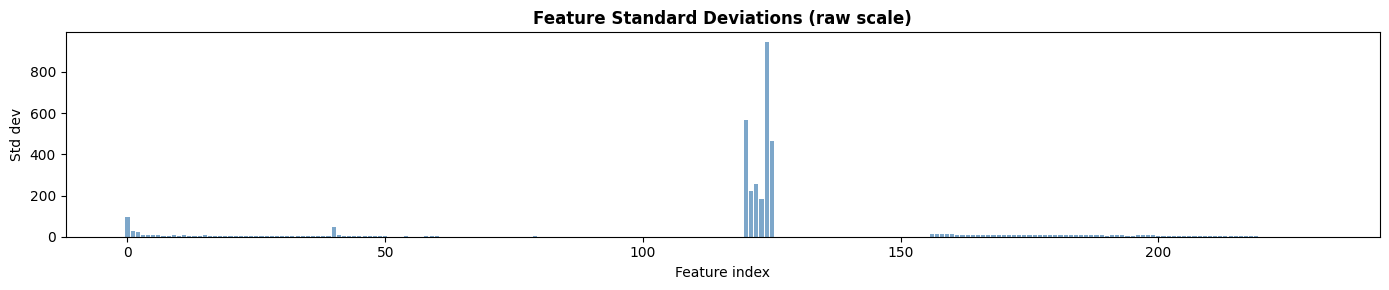

In [5]:
# Replace NaN/Inf with column medians
X_clean = X_raw.copy()
for col in range(X_clean.shape[1]):
    bad = ~np.isfinite(X_clean[:, col])
    if bad.any():
        X_clean[bad, col] = np.nanmedian(X_clean[:, col])

# Remove near-zero-variance features
var       = X_clean.var(axis=0)
keep_mask = var > 1e-8
X_clean   = X_clean[:, keep_mask]
print(f'Features after removing zero-variance: {X_raw.shape[1]} → {X_clean.shape[1]}')

# Quick feature distribution overview
fig, ax = plt.subplots(figsize=(14, 3))
ax.bar(range(X_clean.shape[1]), X_clean.std(axis=0), color='steelblue', alpha=0.7)
ax.set_xlabel('Feature index'); ax.set_ylabel('Std dev')
ax.set_title('Feature Standard Deviations (raw scale)', fontweight='bold')
plt.tight_layout(); plt.show()

## 5 — Dimensionality Reduction: StandardScaler → PCA → UMAP

PCA: 232 → 67 dims (95.0% variance retained)


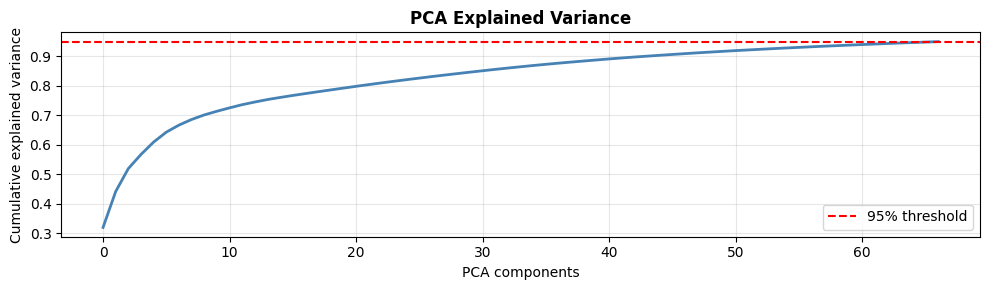


Fitting UMAP 15D for DBSCAN...
UMAP 15D done: (56236, 15)
Fitting UMAP 2D for plotting...
UMAP 2D done: (56236, 2)


In [6]:
# ── Step 1: Standardise ──────────────────────────────────────────────
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)

# ── Step 2: PCA to 95% variance ──────────────────────────────────────
pca      = PCA(n_components=0.95, random_state=SEED)
X_pca    = pca.fit_transform(X_scaled)
print(f'PCA: {X_clean.shape[1]} → {X_pca.shape[1]} dims '
      f'({pca.explained_variance_ratio_.sum()*100:.1f}% variance retained)')

# Plot explained variance
fig, ax = plt.subplots(figsize=(10, 3))
cumvar = np.cumsum(pca.explained_variance_ratio_)
ax.plot(cumvar, color='steelblue', linewidth=2)
ax.axhline(0.95, color='red', linestyle='--', label='95% threshold')
ax.set_xlabel('PCA components'); ax.set_ylabel('Cumulative explained variance')
ax.set_title('PCA Explained Variance', fontweight='bold')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ── Step 3: UMAP 15D (for DBSCAN) ───────────────────────────────────
print('\nFitting UMAP 15D for DBSCAN...')
reducer_nd = umap.UMAP(n_components=15, n_neighbors=30,
                        min_dist=0.0, metric='euclidean',
                        random_state=SEED, low_memory=True)
X_umap_nd  = reducer_nd.fit_transform(X_pca)
print(f'UMAP 15D done: {X_umap_nd.shape}')

# ── Step 4: UMAP 2D (for plotting) ───────────────────────────────────
print('Fitting UMAP 2D for plotting...')
reducer_2d = umap.UMAP(n_components=2, n_neighbors=30,
                        min_dist=0.1, metric='euclidean',
                        random_state=SEED, low_memory=True)
X_umap_2d  = reducer_2d.fit_transform(X_pca)
df['umap_x'] = X_umap_2d[:, 0]
df['umap_y'] = X_umap_2d[:, 1]
print(f'UMAP 2D done: {X_umap_2d.shape}')

## 6 — DBSCAN Parameter Tuning: k-NN Distance Plot

Using k=30 for k-NN distance plot


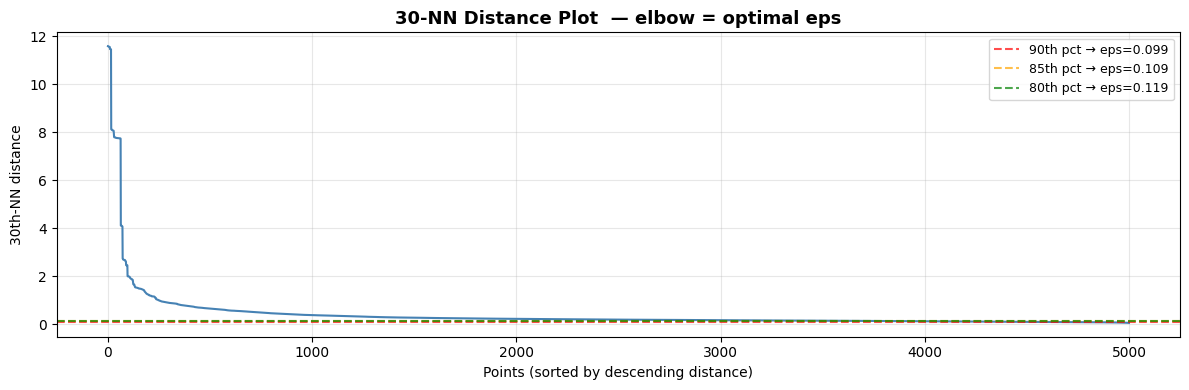


Candidate eps values:
  92th pct → eps = 0.0943
  90th pct → eps = 0.0986
  87th pct → eps = 0.1053
  85th pct → eps = 0.1093
  82th pct → eps = 0.1149
  80th pct → eps = 0.1195
  75th pct → eps = 0.1293


In [7]:
K = max(5, X_umap_nd.shape[1] * 2)   # rule of thumb: minPts ≥ 2×dims, at least 5
print(f'Using k={K} for k-NN distance plot')

# Subsample for speed if dataset is large
N_SAMPLE = min(5000, len(X_umap_nd))
idx_sub  = np.random.choice(len(X_umap_nd), N_SAMPLE, replace=False)
X_sub    = X_umap_nd[idx_sub]

nbrs     = NearestNeighbors(n_neighbors=K, metric='euclidean', n_jobs=-1).fit(X_sub)
dists, _ = nbrs.kneighbors(X_sub)
k_dists  = np.sort(dists[:, K-1])[::-1]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(k_dists, linewidth=1.5, color='steelblue')
ax.set_title(f'{K}-NN Distance Plot  — elbow = optimal eps',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Points (sorted by descending distance)')
ax.set_ylabel(f'{K}th-NN distance')
ax.grid(alpha=0.3)

# Mark candidate eps values
for pct, col in zip([90, 85, 80], ['red','orange','green']):
    eps_val = np.percentile(k_dists, 100 - pct)
    ax.axhline(eps_val, color=col, linestyle='--', alpha=0.7,
               label=f'{pct}th pct → eps={eps_val:.3f}')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'knn_distance_plot.png'), dpi=150)
plt.show()

print('\nCandidate eps values:')
eps_candidates = []
for pct in [92, 90, 87, 85, 82, 80, 75]:
    val = np.percentile(k_dists, 100 - pct)
    eps_candidates.append(round(val, 4))
    print(f'  {pct}th pct → eps = {val:.4f}')
eps_candidates = sorted(set(eps_candidates))

## 7 — Grid Search: eps × min_samples

In [8]:
min_samples_range = [5, 8, 10, 15, 20]
results = []

print(f'Grid: {len(eps_candidates)} eps × {len(min_samples_range)} min_samples '
      f'= {len(eps_candidates)*len(min_samples_range)} combos')

for eps in tqdm(eps_candidates, desc='Grid search'):
    for ms in min_samples_range:
        db     = DBSCAN(eps=eps, min_samples=ms, metric='euclidean', n_jobs=-1)
        labels = db.fit_predict(X_umap_nd)
        n_cl   = len(set(labels)) - (1 if -1 in labels else 0)
        noise  = (labels == -1).sum() / len(labels) * 100

        if n_cl >= 2:
            mask = labels != -1
            sil  = silhouette_score(X_umap_nd[mask], labels[mask]) if mask.sum() > 1 else -1
            dbi  = davies_bouldin_score(X_umap_nd[mask], labels[mask]) if mask.sum() > 1 else 99
        else:
            sil, dbi = -1, 99

        ari = adjusted_rand_score(df['label'].values, labels)
        nmi = normalized_mutual_info_score(df['label'].values, labels)

        results.append({'eps': eps, 'min_samples': ms, 'n_clusters': n_cl,
                        'noise_%': round(noise,1), 'silhouette': round(sil,4),
                        'davies_bouldin': round(dbi,4),
                        'ARI': round(ari,4), 'NMI': round(nmi,4)})

res_df = pd.DataFrame(results)
# Score = high silhouette + low noise + n_clusters in sensible range
res_df['score'] = res_df['silhouette'] - res_df['noise_%']/200
res_df = res_df.sort_values('score', ascending=False)

print('\nTop 12 combinations:')
display(res_df.head(12).drop('score', axis=1).reset_index(drop=True))
res_df.to_csv(os.path.join(SAVE_DIR, 'dbscan_grid_search.csv'), index=False)

Grid: 7 eps × 5 min_samples = 35 combos


Grid search:   0%|          | 0/7 [00:00<?, ?it/s]


Top 12 combinations:


,eps,min_samples,n_clusters,noise_%,silhouette,davies_bouldin,ARI,NMI
0,0.1293,20,94,1.9,0.7387,0.3028,0.1084,0.4922
1,0.1195,15,97,2.3,0.7278,0.3212,0.1067,0.4875
2,0.1149,15,101,2.7,0.7256,0.3367,0.1061,0.4880
3,0.1293,15,91,1.6,0.7159,0.3117,0.1113,0.4916
4,0.1053,20,115,4.3,0.7247,0.3360,0.0928,0.4747
5,0.1149,10,103,2.2,0.7089,0.3263,0.1083,0.4869
6,0.0986,20,124,5.5,0.7226,0.3521,0.0877,0.4682
7,0.1093,10,105,2.7,0.7066,0.3313,0.1070,0.4847
8,0.1093,15,105,3.3,0.7031,0.3445,0.1047,0.4855
9,0.1149,20,105,3.0,0.6977,0.3440,0.1026,0.4838


## 8 — Final DBSCAN Run

In [9]:
# Auto-pick best params: good silhouette, noise < 25%, n_clusters >= 2
valid_rows = res_df[(res_df['n_clusters'] >= 2) & (res_df['noise_%'] < 25)]
if len(valid_rows) == 0:
    valid_rows = res_df[res_df['n_clusters'] >= 2]
best_row = valid_rows.iloc[0]

BEST_EPS = best_row['eps']
BEST_MS  = int(best_row['min_samples'])
print(f'Selected: eps={BEST_EPS}, min_samples={BEST_MS}')
print(f'  Clusters   : {int(best_row["n_clusters"])}')
print(f'  Noise      : {best_row["noise_%"]}%')
print(f'  Silhouette : {best_row["silhouette"]}')
print(f'  ARI        : {best_row["ARI"]}')
print(f'  NMI        : {best_row["NMI"]}')

db_final       = DBSCAN(eps=BEST_EPS, min_samples=BEST_MS, metric='euclidean', n_jobs=-1)
cluster_labels = db_final.fit_predict(X_umap_nd)
df['cluster']  = cluster_labels

n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
n_noise    = (cluster_labels == -1).sum()
print(f'\nFinal: {n_clusters} clusters | {n_noise:,} noise pts '
      f'({n_noise/len(cluster_labels)*100:.1f}%)')

Selected: eps=0.1293, min_samples=20
  Clusters   : 94
  Noise      : 1.9%
  Silhouette : 0.7386999726295471
  ARI        : 0.1084
  NMI        : 0.4922

Final: 94 clusters | 1,063 noise pts (1.9%)


## 9 — Visualisations

In [10]:
# ── Palettes ─────────────────────────────────────────────────────────
CLASS_PAL   = sns.color_palette('tab10', 6)
CLUSTER_PAL = sns.color_palette('Set2', max(n_clusters, 2))
MACHINE_PAL = {'Machine 1':'#e74c3c','Machine 2':'#3498db','Machine 3':'#2ecc71'}
STATE_PAL   = {'Normal':'#2ecc71','Abnormal':'#e74c3c'}

def scatter(ax, x, y, c_list, labels_list, title, xlabel='UMAP 1', ylabel='UMAP 2', s=8, alpha=0.6):
    for val, col in zip(sorted(set(labels_list)), c_list):
        mask = np.array(labels_list) == val
        ax.scatter(np.array(x)[mask], np.array(y)[mask],
                   c=[col], label=str(val), s=s, alpha=alpha, linewidths=0)
    ax.set_title(title, fontsize=11, fontweight='bold', pad=6)
    ax.set_xlabel(xlabel, fontsize=9); ax.set_ylabel(ylabel, fontsize=9)
    ax.tick_params(labelsize=7); ax.grid(alpha=0.15)
    ax.legend(loc='best', fontsize=7, markerscale=2, framealpha=0.8)

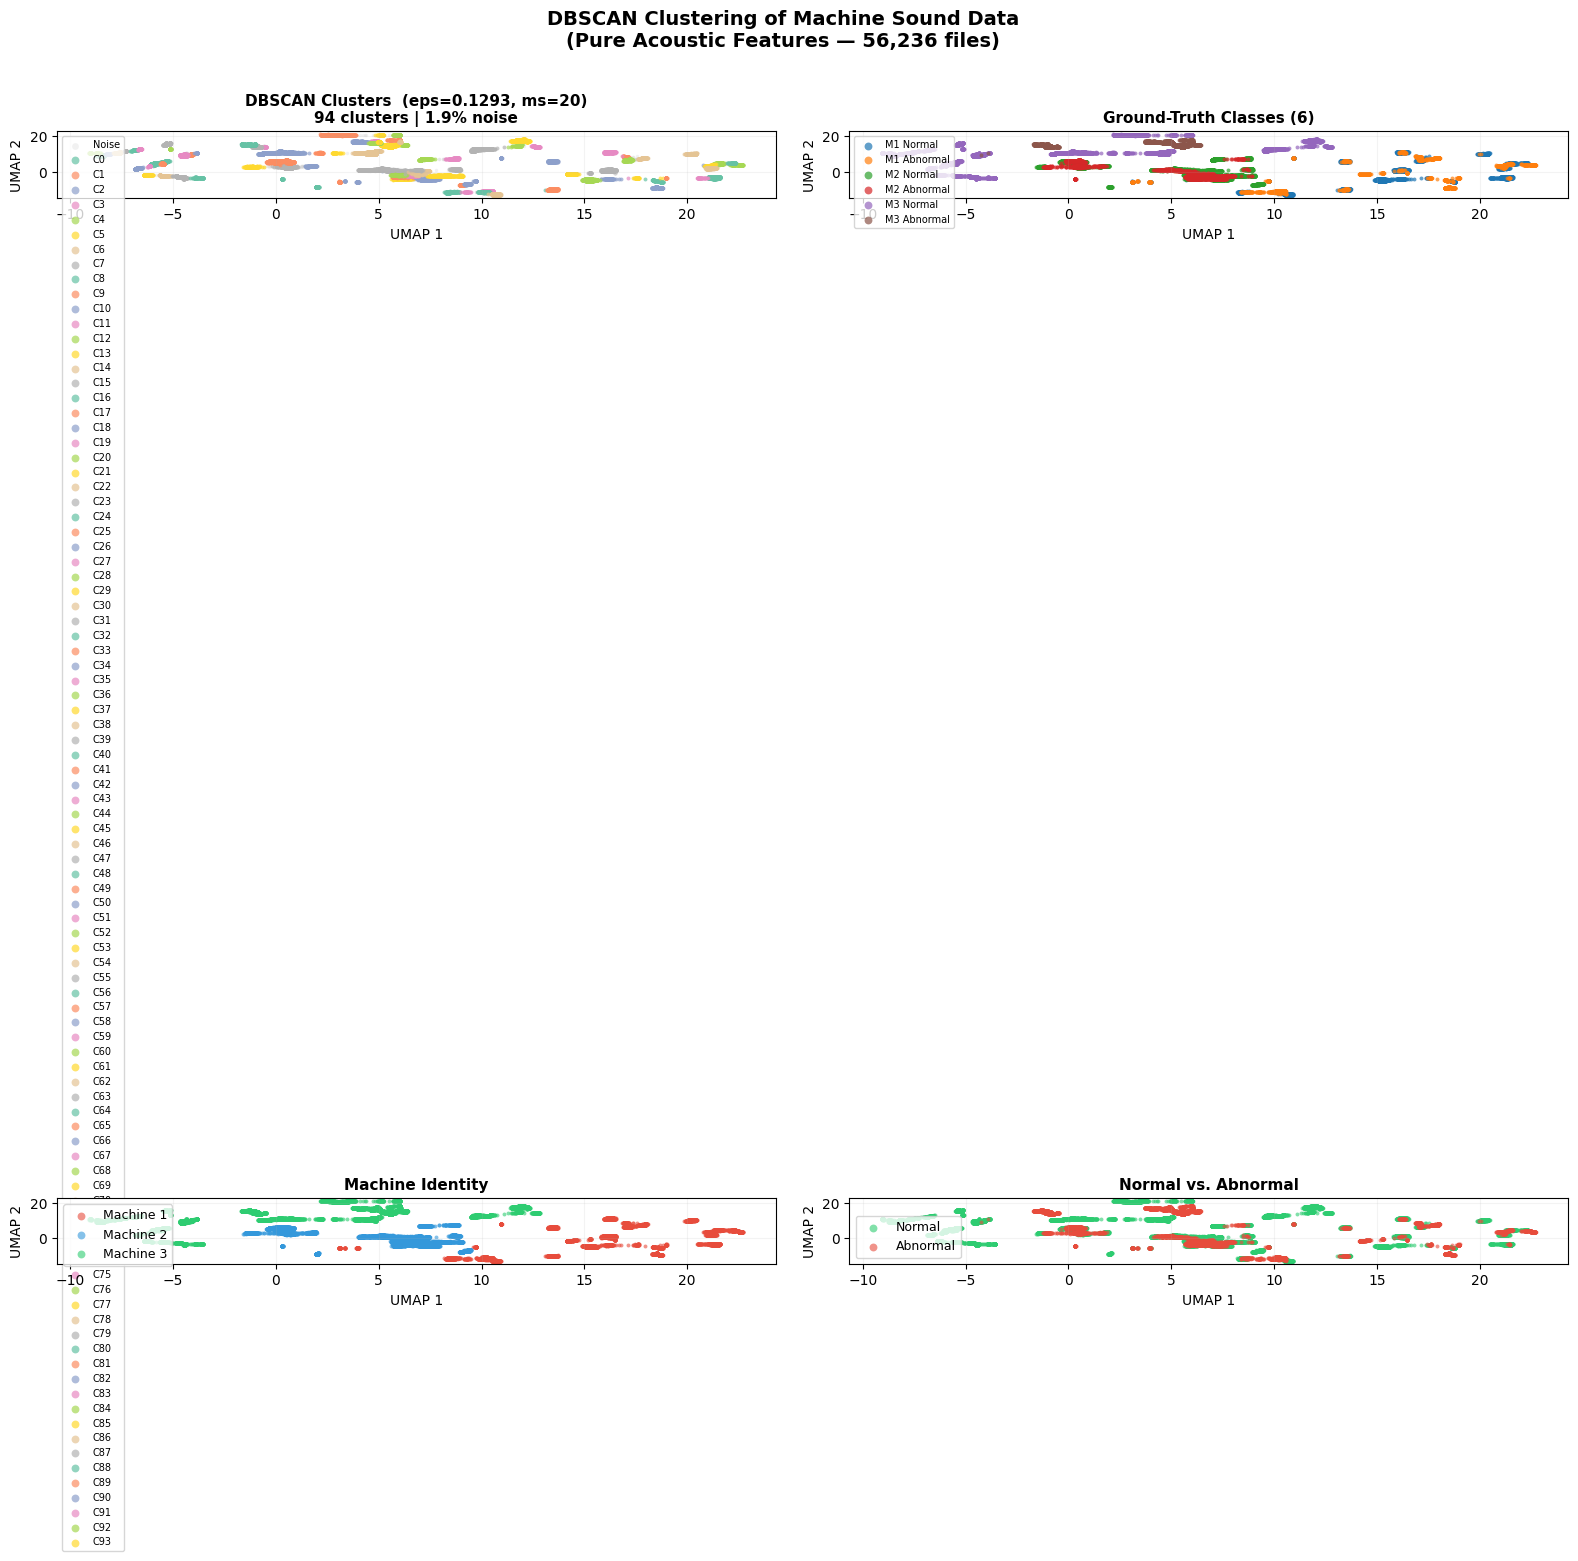

Saved → plot1_overview.png


In [11]:
# ════════════════════════════════════════════════════════════════════
# PLOT 1 — 2×2 overview
# ════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
fig.suptitle('DBSCAN Clustering of Machine Sound Data\n'
             f'(Pure Acoustic Features — {len(df):,} files)',
             fontsize=14, fontweight='bold', y=1.01)

ux, uy = df['umap_x'].values, df['umap_y'].values

# A — DBSCAN clusters
ax = axes[0, 0]
noise_m = df['cluster'] == -1
ax.scatter(ux[noise_m], uy[noise_m], c='lightgrey', s=6, alpha=0.3,
           label='Noise', linewidths=0)
for cid in sorted(set(cluster_labels) - {-1}):
    m = df['cluster'] == cid
    ax.scatter(ux[m], uy[m], c=[CLUSTER_PAL[cid % len(CLUSTER_PAL)]],
               s=8, alpha=0.7, label=f'C{cid}', linewidths=0)
ax.set_title(f'DBSCAN Clusters  (eps={BEST_EPS}, ms={BEST_MS})\n'
             f'{n_clusters} clusters | {n_noise/len(df)*100:.1f}% noise',
             fontsize=11, fontweight='bold')
ax.legend(loc='best', fontsize=7, markerscale=2)
ax.set_xlabel('UMAP 1'); ax.set_ylabel('UMAP 2'); ax.grid(alpha=0.15)

# B — Ground truth (all 6 classes)
ax = axes[0, 1]
for lbl in range(6):
    m = df['label'] == lbl
    ax.scatter(ux[m], uy[m], c=[CLASS_PAL[lbl]], s=8, alpha=0.7,
               label=CLASSES[lbl], linewidths=0)
ax.set_title('Ground-Truth Classes (6)', fontsize=11, fontweight='bold')
ax.legend(loc='best', fontsize=7, markerscale=2)
ax.set_xlabel('UMAP 1'); ax.set_ylabel('UMAP 2'); ax.grid(alpha=0.15)

# C — Machine identity
ax = axes[1, 0]
for mnum, mname in MACHINE_NAMES.items():
    m = df['machine'] == mnum
    ax.scatter(ux[m], uy[m], c=[MACHINE_PAL[mname]], s=8, alpha=0.6,
               label=mname, linewidths=0)
ax.set_title('Machine Identity', fontsize=11, fontweight='bold')
ax.legend(loc='best', fontsize=9, markerscale=2)
ax.set_xlabel('UMAP 1'); ax.set_ylabel('UMAP 2'); ax.grid(alpha=0.15)

# D — Normal vs Abnormal
ax = axes[1, 1]
for sname, col in STATE_PAL.items():
    m = df['state'].str.capitalize() == sname
    ax.scatter(ux[m], uy[m], c=[col], s=8, alpha=0.6,
               label=sname, linewidths=0)
ax.set_title('Normal vs. Abnormal', fontsize=11, fontweight='bold')
ax.legend(loc='best', fontsize=9, markerscale=2)
ax.set_xlabel('UMAP 1'); ax.set_ylabel('UMAP 2'); ax.grid(alpha=0.15)

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'plot1_overview.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved → plot1_overview.png')

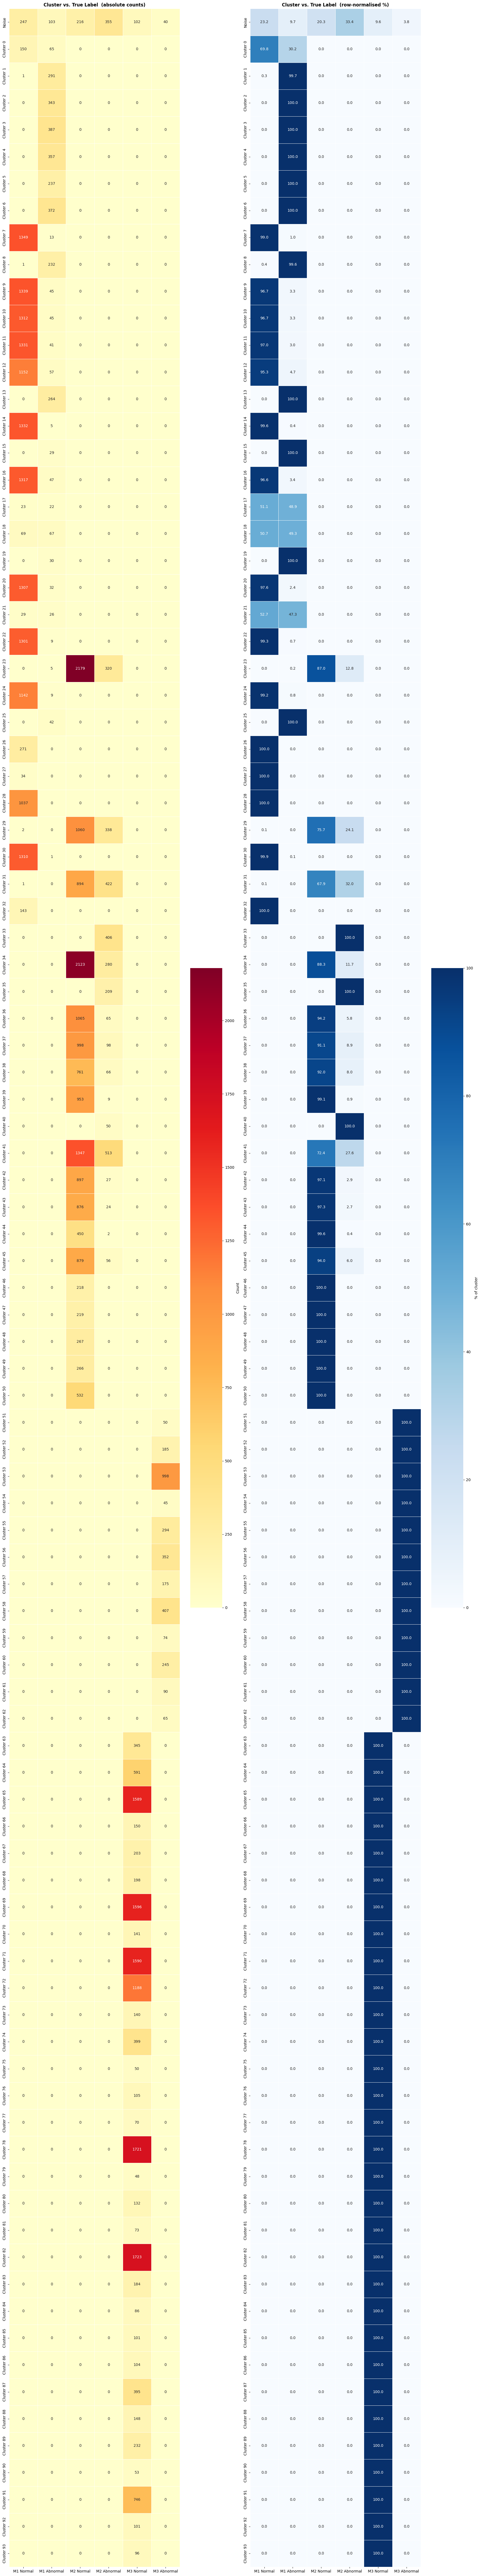

Saved → plot2_cluster_label_heatmap.png


In [12]:
# ════════════════════════════════════════════════════════════════════
# PLOT 2 — Cluster × True-Label heatmap
# ════════════════════════════════════════════════════════════════════
ct = pd.crosstab(df['cluster'], df['label'])
ct.columns = [CLASSES[c] for c in ct.columns]
ct.index   = [f'Cluster {i}' if i != -1 else 'Noise' for i in ct.index]

# Row-normalise to show composition
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, max(5, n_clusters+2)))
sns.heatmap(ct, annot=True, fmt='d', cmap='YlOrRd', ax=ax1,
            linewidths=0.5, cbar_kws={'label': 'Count'})
ax1.set_title('Cluster vs. True Label  (absolute counts)',
              fontsize=12, fontweight='bold')

sns.heatmap(ct_pct.round(1), annot=True, fmt='.1f', cmap='Blues', ax=ax2,
            linewidths=0.5, cbar_kws={'label': '% of cluster'})
ax2.set_title('Cluster vs. True Label  (row-normalised %)',
              fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'plot2_cluster_label_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved → plot2_cluster_label_heatmap.png')

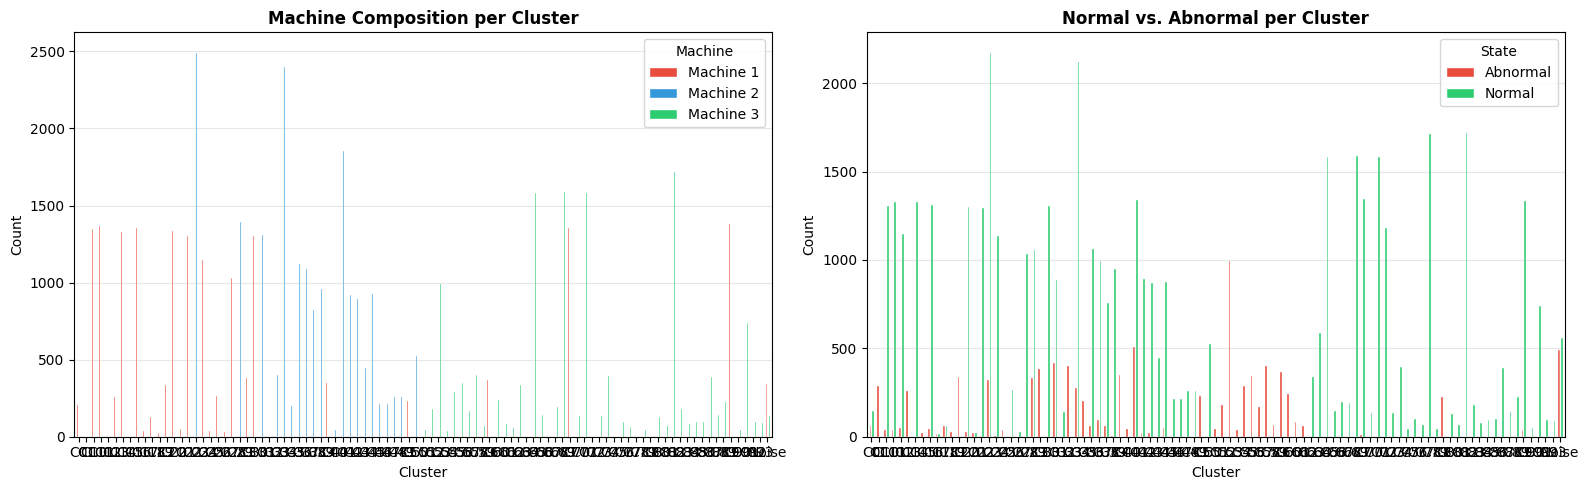

Saved → plot3_cluster_breakdown.png


In [13]:
# ════════════════════════════════════════════════════════════════════
# PLOT 3 — Per-cluster breakdown: machine + state stacked bars
# ════════════════════════════════════════════════════════════════════
df['cluster_label'] = df['cluster'].apply(lambda c: f'C{c}' if c != -1 else 'Noise')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Machine breakdown
machine_ct = df.groupby(['cluster_label','machine']).size().unstack(fill_value=0)
machine_ct.columns = [MACHINE_NAMES.get(c, str(c)) for c in machine_ct.columns]
machine_ct.plot(kind='bar', ax=ax1, color=['#e74c3c','#3498db','#2ecc71'],
                edgecolor='white', width=0.75)
ax1.set_title('Machine Composition per Cluster', fontweight='bold')
ax1.set_xlabel('Cluster'); ax1.set_ylabel('Count')
ax1.legend(title='Machine'); ax1.grid(axis='y', alpha=0.3)
ax1.tick_params(axis='x', rotation=0)

# Normal/Abnormal breakdown
state_ct = df.groupby(['cluster_label','state']).size().unstack(fill_value=0)
state_ct.columns = [s.capitalize() for s in state_ct.columns]
state_ct.plot(kind='bar', ax=ax2,
              color=['#e74c3c' if 'ab' in c.lower() else '#2ecc71'
                     for c in state_ct.columns],
              edgecolor='white', width=0.75)
ax2.set_title('Normal vs. Abnormal per Cluster', fontweight='bold')
ax2.set_xlabel('Cluster'); ax2.set_ylabel('Count')
ax2.legend(title='State'); ax2.grid(axis='y', alpha=0.3)
ax2.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'plot3_cluster_breakdown.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved → plot3_cluster_breakdown.png')

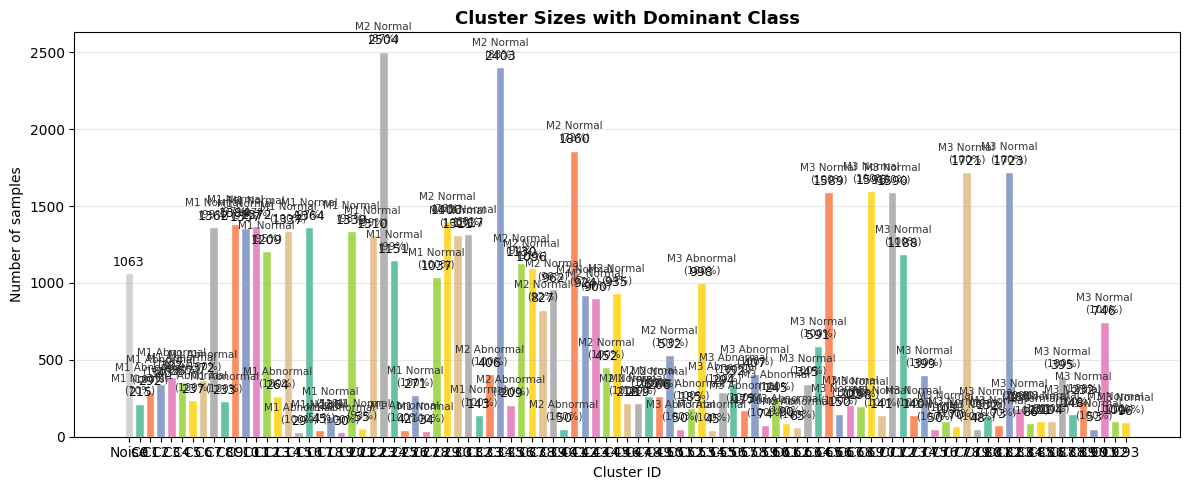

Saved → plot4_cluster_sizes.png


In [14]:
# ════════════════════════════════════════════════════════════════════
# PLOT 4 — Cluster sizes + dominant class annotation
# ════════════════════════════════════════════════════════════════════
cluster_ids   = sorted(df['cluster'].unique())
cluster_sizes = [( df['cluster'] == cid).sum() for cid in cluster_ids]
bar_colors    = ['lightgrey' if cid == -1 else CLUSTER_PAL[cid % len(CLUSTER_PAL)]
                 for cid in cluster_ids]
bar_labels    = [f'Noise' if cid == -1 else f'C{cid}' for cid in cluster_ids]

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(bar_labels, cluster_sizes, color=bar_colors, edgecolor='white')
ax.bar_label(bars, padding=3, fontsize=9)

# Annotate dominant class
for i, cid in enumerate(cluster_ids):
    if cid == -1: continue
    sub  = df[df['cluster'] == cid]['label']
    dom  = sub.value_counts().idxmax()
    pct  = sub.value_counts().iloc[0] / len(sub) * 100
    ax.text(i, cluster_sizes[i] + max(cluster_sizes)*0.02,
            f'{CLASSES[dom]}\n({pct:.0f}%)',
            ha='center', va='bottom', fontsize=7.5, color='#333')

ax.set_title('Cluster Sizes with Dominant Class', fontsize=13, fontweight='bold')
ax.set_xlabel('Cluster ID'); ax.set_ylabel('Number of samples')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'plot4_cluster_sizes.png'), dpi=150)
plt.show()
print('Saved → plot4_cluster_sizes.png')

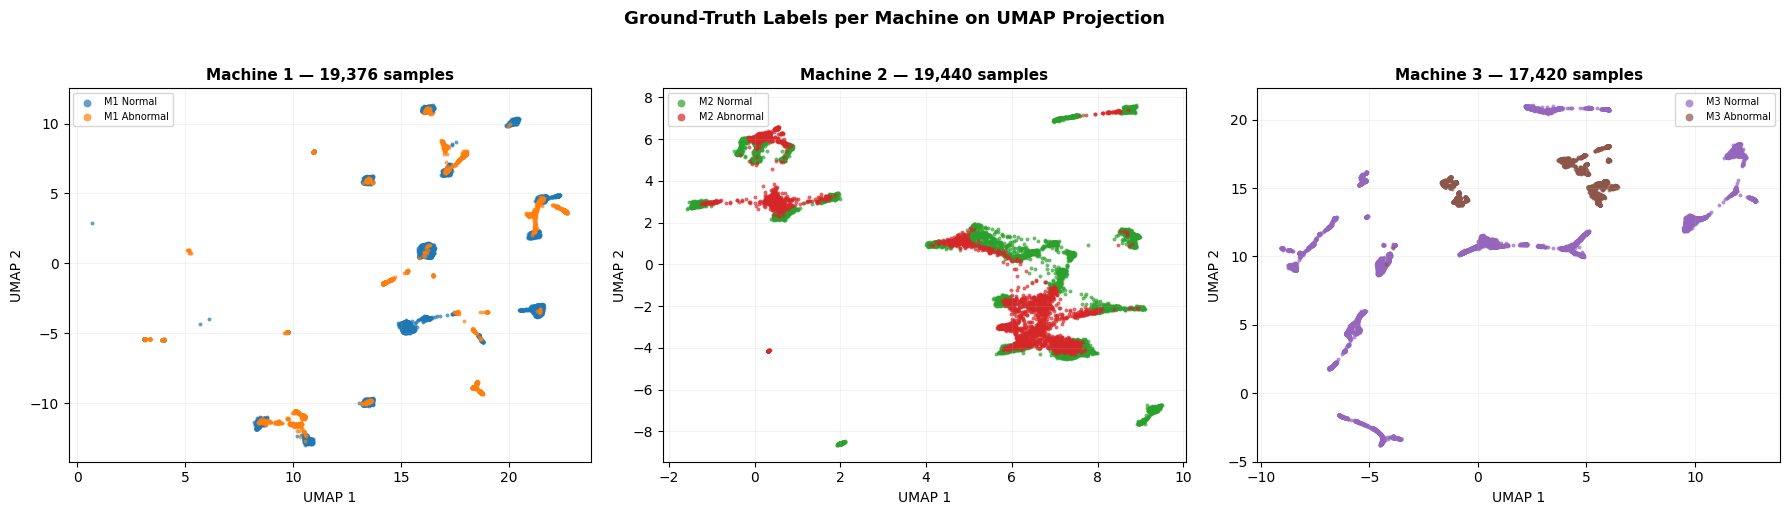

Saved → plot5_per_machine.png


In [15]:
# ════════════════════════════════════════════════════════════════════
# PLOT 5 — UMAP faceted by machine (3 subplots)
# ════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, mnum in zip(axes, [1, 2, 3]):
    sub  = df[df['machine'] == mnum]
    for lbl in sorted(sub['label'].unique()):
        m = sub['label'] == lbl
        ax.scatter(sub.loc[m,'umap_x'], sub.loc[m,'umap_y'],
                   c=[CLASS_PAL[lbl]], s=8, alpha=0.7,
                   label=CLASSES[lbl], linewidths=0)
    ax.set_title(f'{MACHINE_NAMES[mnum]} — {len(sub):,} samples',
                 fontsize=11, fontweight='bold')
    ax.legend(loc='best', fontsize=7, markerscale=2)
    ax.set_xlabel('UMAP 1'); ax.set_ylabel('UMAP 2')
    ax.grid(alpha=0.15)

plt.suptitle('Ground-Truth Labels per Machine on UMAP Projection',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'plot5_per_machine.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved → plot5_per_machine.png')

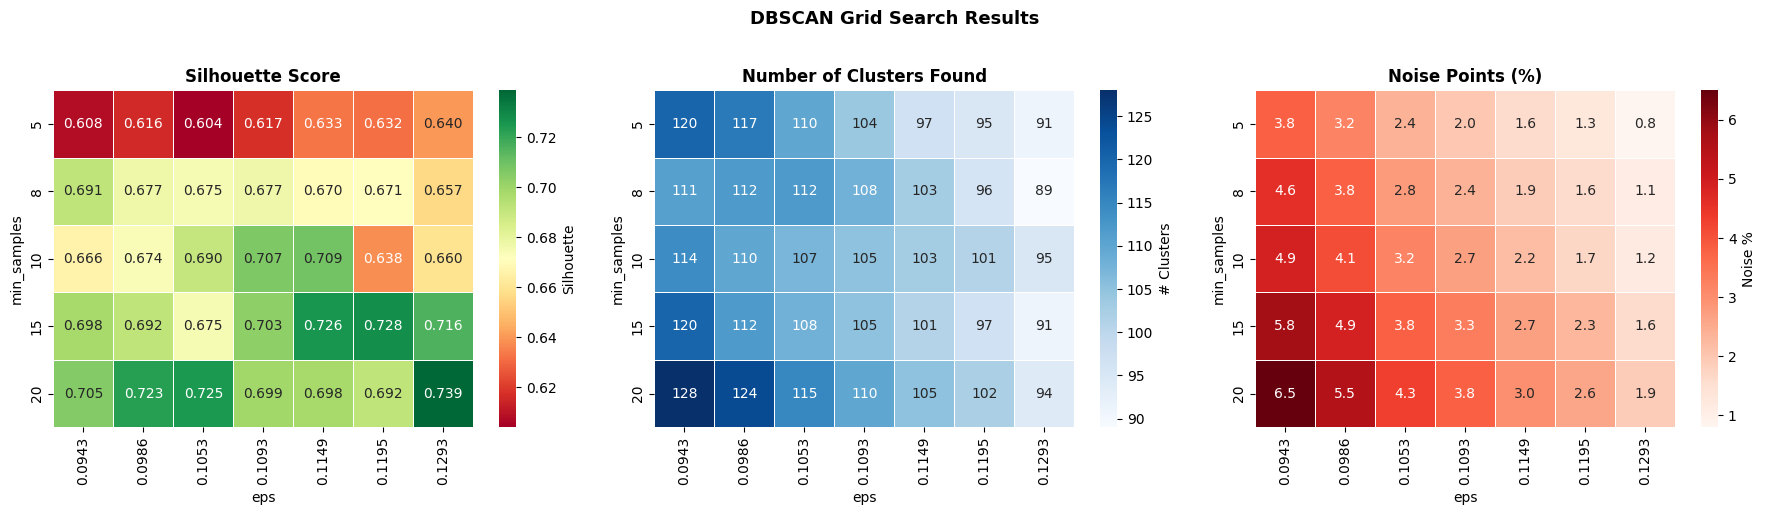

Saved → plot6_grid_search.png


In [16]:
# ════════════════════════════════════════════════════════════════════
# PLOT 6 — Grid search heatmap (Silhouette vs eps × min_samples)
# ════════════════════════════════════════════════════════════════════
pivot_sil   = res_df.pivot_table('silhouette',   'min_samples', 'eps')
pivot_nclus = res_df.pivot_table('n_clusters',   'min_samples', 'eps')
pivot_noise = res_df.pivot_table('noise_%',      'min_samples', 'eps')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.heatmap(pivot_sil,   annot=True, fmt='.3f', cmap='RdYlGn', ax=axes[0],
            linewidths=0.5, cbar_kws={'label':'Silhouette'})
axes[0].set_title('Silhouette Score', fontweight='bold')

sns.heatmap(pivot_nclus, annot=True, fmt='.0f',  cmap='Blues',  ax=axes[1],
            linewidths=0.5, cbar_kws={'label':'# Clusters'})
axes[1].set_title('Number of Clusters Found', fontweight='bold')

sns.heatmap(pivot_noise, annot=True, fmt='.1f',  cmap='Reds',   ax=axes[2],
            linewidths=0.5, cbar_kws={'label':'Noise %'})
axes[2].set_title('Noise Points (%)', fontweight='bold')

plt.suptitle('DBSCAN Grid Search Results', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'plot6_grid_search.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved → plot6_grid_search.png')

## 10 — Quantitative Summary

In [17]:
non_noise  = cluster_labels != -1
X_eval     = X_umap_nd[non_noise]
y_clust_ev = cluster_labels[non_noise]
y_gt_ev    = df['label'].values[non_noise]

sil = silhouette_score(X_eval, y_clust_ev)           if len(np.unique(y_clust_ev))>1 else -1
dbi = davies_bouldin_score(X_eval, y_clust_ev)       if len(np.unique(y_clust_ev))>1 else 99
ari = adjusted_rand_score(y_gt_ev, y_clust_ev)
nmi = normalized_mutual_info_score(y_gt_ev, y_clust_ev)

print('═'*58)
print('   DBSCAN ACOUSTIC CLUSTERING — EVALUATION SUMMARY')
print('═'*58)
print(f'  Feature type         : Hand-crafted acoustic (librosa)')
print(f'  Feature dims         : {X_clean.shape[1]}')
print(f'  After PCA            : {X_pca.shape[1]} dims')
print(f'  After UMAP (DBSCAN)  : {X_umap_nd.shape[1]} dims')
print(f'  Total samples        : {len(df):,}')
print(f'  Noise points         : {n_noise:,} ({n_noise/len(df)*100:.1f}%)')
print(f'  Clusters found       : {n_clusters}')
print(f'  eps                  : {BEST_EPS}')
print(f'  min_samples          : {BEST_MS}')
print('─'*58)
print(f'  Silhouette Score     : {sil:.4f}  (−1 worst → +1 best)')
print(f'  Davies-Bouldin Index : {dbi:.4f}  (lower is better)')
print(f'  Adjusted Rand Index  : {ari:.4f}  (0 random → 1 perfect)')
print(f'  Norm. Mutual Info    : {nmi:.4f}  (0 none → 1 perfect)')
print('─'*58)
print('\n  Cluster → dominant class mapping:')
for cid in sorted(set(cluster_labels) - {-1}):
    sub   = df[df['cluster'] == cid]
    dom   = sub['label'].value_counts().idxmax()
    pct   = sub['label'].value_counts().iloc[0] / len(sub) * 100
    print(f'    Cluster {cid:2d} → {CLASSES[dom]:15s}  ({pct:.1f}% pure | {len(sub):,} samples)')
print('═'*58)

══════════════════════════════════════════════════════════
   DBSCAN ACOUSTIC CLUSTERING — EVALUATION SUMMARY
══════════════════════════════════════════════════════════
  Feature type         : Hand-crafted acoustic (librosa)
  Feature dims         : 232
  After PCA            : 67 dims
  After UMAP (DBSCAN)  : 15 dims
  Total samples        : 56,236
  Noise points         : 1,063 (1.9%)
  Clusters found       : 94
  eps                  : 0.1293
  min_samples          : 20
──────────────────────────────────────────────────────────
  Silhouette Score     : 0.7387  (−1 worst → +1 best)
  Davies-Bouldin Index : 0.3028  (lower is better)
  Adjusted Rand Index  : 0.1111  (0 random → 1 perfect)
  Norm. Mutual Info    : 0.5011  (0 none → 1 perfect)
──────────────────────────────────────────────────────────

  Cluster → dominant class mapping:
    Cluster  0 → M1 Normal        (69.8% pure | 215 samples)
    Cluster  1 → M1 Abnormal      (99.7% pure | 292 samples)
    Cluster  2 → M1 Abnormal 

## 11 — Save Results

In [18]:
out = df[['file_path','label','machine','state','class_name','cluster','umap_x','umap_y']]
out_path = os.path.join(SAVE_DIR, 'dbscan_cluster_results.csv')
out.to_csv(out_path, index=False)
print(f'Results saved → {out_path}')
print(f'Grid search  → {os.path.join(SAVE_DIR, "dbscan_grid_search.csv")}')
print('\n✅ All done!')

Results saved → /kaggle/working/dbscan_cluster_results.csv
Grid search  → /kaggle/working/dbscan_grid_search.csv

✅ All done!
